## Load the integrated dataset through DuckDB

In [1]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
from config import PROCESSED_DIR, FIGURE_DIR

In [3]:
data_file = (PROCESSED_DIR / "electricity_data.parquet").as_posix()

con = duckdb.connect()

sns.set_theme(style="whitegrid")

## Figure 1: Hourly electricity consumption

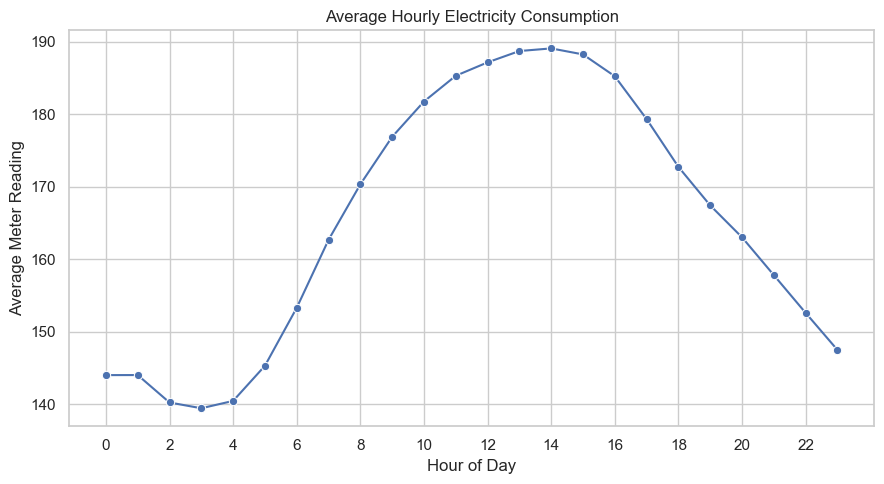

In [4]:
query = """
WITH building_hourly AS (
    SELECT
        building_id,
        hour,
        AVG(meter_reading) AS avg_consumption
    FROM read_parquet(?)
    GROUP BY building_id, hour
)
SELECT
    hour,
    AVG(avg_consumption) AS mean_consumption
FROM building_hourly
GROUP BY hour
ORDER BY hour
"""

hourly = con.execute(query, [data_file]).df()

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=hourly,
    x="hour",
    y="mean_consumption",
    marker="o"
)

plt.title("Average Hourly Electricity Consumption")
plt.xlabel("Hour of Day")
plt.ylabel("Average Meter Reading")
plt.xticks(range(0, 24, 2))

plt.tight_layout()
#plt.savefig(FIGURE_DIR / "average_hourly_electricity_consumption.png", bbox_inches="tight")
plt.show()

## Figure 2: Building-use categories

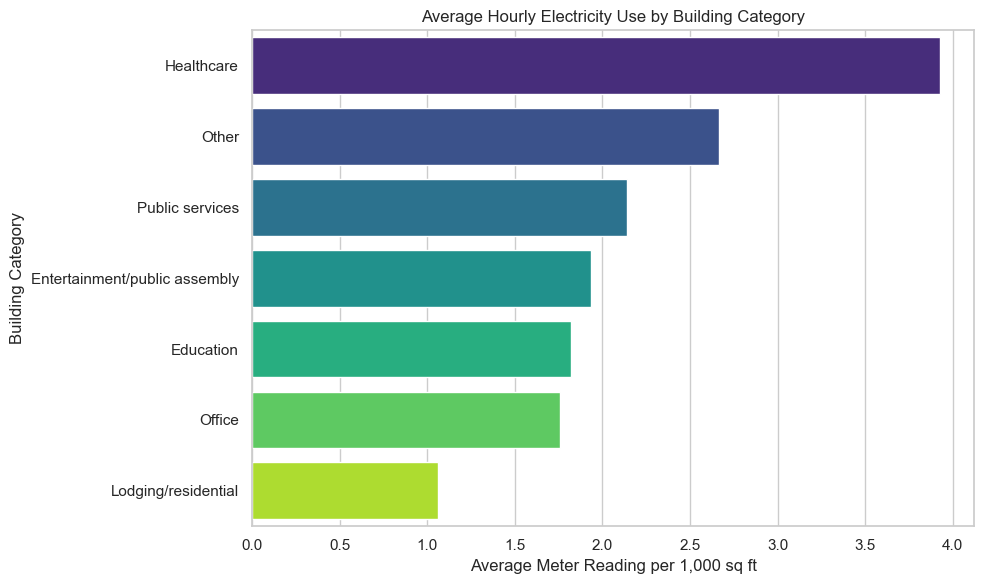

In [5]:
query = """
WITH building_avg AS (
    SELECT
        building_id,
        primary_use,
        square_feet,
        AVG(meter_reading) AS avg_consumption
    FROM read_parquet(?)
    WHERE square_feet > 0
    GROUP BY building_id, primary_use, square_feet
)
SELECT
    primary_use,
    COUNT(*) AS buildings,
    AVG(
        avg_consumption / square_feet * 1000
    ) AS consumption_per_1000_sqft
FROM building_avg
GROUP BY primary_use
HAVING COUNT(*) >= 20
ORDER BY consumption_per_1000_sqft DESC
"""

building_use = con.execute(query, [data_file]).df()

plt.figure(figsize=(10, 6))

sns.barplot(
    data=building_use,
    x="consumption_per_1000_sqft",
    y="primary_use",
    hue="primary_use",
    palette="viridis",
    dodge=False,
    legend=False,
    saturation=1,
)

plt.title("Average Hourly Electricity Use by Building Category")
plt.xlabel("Average Meter Reading per 1,000 sq ft")
plt.ylabel("Building Category")

plt.tight_layout()
#plt.savefig(FIGURE_DIR / "average_hourly_electricity_use_by_building_category.png", bbox_inches="tight")
plt.show()

## Figure 3: Temperature versus electricity consumption

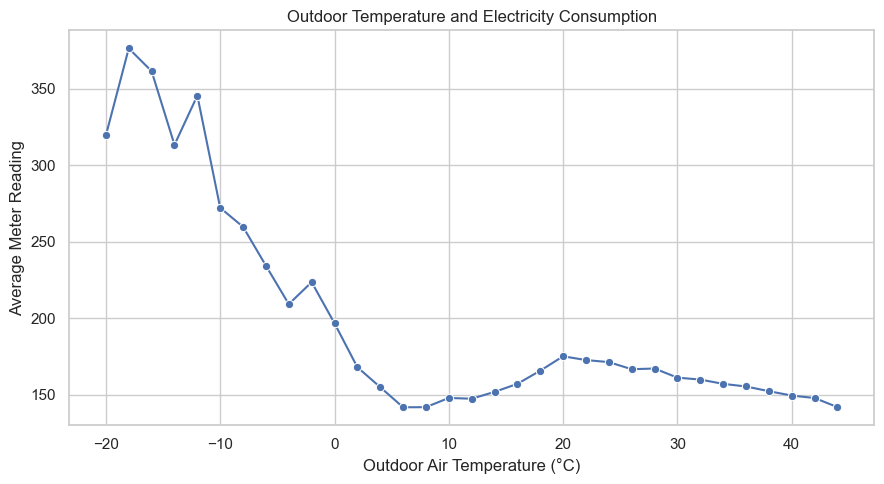

In [6]:
query = """
SELECT
    FLOOR(air_temperature / 2) * 2 AS temp_bin,
    COUNT(*) AS observations,
    AVG(meter_reading) AS mean_consumption
FROM read_parquet(?)
WHERE air_temperature IS NOT NULL
  AND air_temperature BETWEEN -20 AND 45
GROUP BY temp_bin
HAVING COUNT(*) >= 1000
ORDER BY temp_bin
"""

temp_relation = con.execute(query, [data_file]).df()

plt.figure(figsize=(9, 5))

sns.lineplot(
    data=temp_relation,
    x="temp_bin",
    y="mean_consumption",
    marker="o"
)

plt.title("Outdoor Temperature and Electricity Consumption")
plt.xlabel("Outdoor Air Temperature (°C)")
plt.ylabel("Average Meter Reading")

plt.tight_layout()
#plt.savefig(FIGURE_DIR / "outdoor_temperature_and_electricity_consumption", bbox_inches="tight")
plt.show()